# 03 · Spectral indices

**Goal:** turn the bands into a few numbers per pixel that react strongly to fire.

**Why it works, in one line:** green leaves reflect a lot of **near-infrared (NIR)** and little red. Char and ash reflect little NIR and more **short-wave infrared (SWIR)**. Each *index* is a small formula that squeezes that contrast into a single number.

| Index | Formula | Measures | Burned pixel |
|---|---|---|---|
| NDVI | (NIR − Red) / (NIR + Red) | greenness | drops |
| NBR | (NIR − SWIR2) / (NIR + SWIR2) | burn-sensitive | drops |
| BAI | 1 / ((0.1 − Red)² + (0.06 − NIR)²) | closeness to the colour of charcoal | rises |
| GEMI | see below | greenness, less affected by haze | drops |

Then we compare dates. **Δ (delta)** means "change": post − pre. For NBR the convention is reversed: **dNBR = pre − post**, so burned = positive.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from common import *

pre, transform, crs = read_reflectance("pre")
post, _, _ = read_reflectance("post")
valid = read_valid()
print("Bands available:", list(pre))

Bands available: ['blue', 'green', 'red', 'nir10', 'nir', 'swir2']


## 1. Normalised difference: the shape behind NDVI and NBR
`(a − b) / (a + b)` always gives a value between −1 and +1, whatever the brightness. That makes it fair to compare a sunny slope with a shaded one.

In [2]:
def _nd(a, b):
    with np.errstate(divide="ignore", invalid="ignore"):
        s = a + b
        return np.where(s > 0, (a - b) / s, np.nan).astype("float32")


def ndvi(nir, red):
    return _nd(nir, red)


def nbr(nir, swir2):
    return _nd(nir, swir2)

**Quick check by hand:** a healthy leaf with NIR = 0.40 and Red = 0.05 gives NDVI = 0.35 / 0.45 ≈ **0.78**. Bare burned soil with NIR = 0.15 and Red = 0.12 gives ≈ **0.11**.

In [3]:
print("leaf  :", ndvi(np.array([0.40]), np.array([0.05])))
print("burned:", ndvi(np.array([0.15]), np.array([0.12])))

leaf  : [0.7777778]
burned: [0.11111111]


## 2. BAI and GEMI
- **BAI** (Martín 1998) measures how *close* a pixel's red/NIR is to charcoal (Red 0.1, NIR 0.06). The closer it is, the smaller the bottom of the fraction, so the bigger the BAI.
- **GEMI** (Pinty & Verstraete 1992) is a greenness index designed to be less affected by haze and smoke.

In [4]:
def bai(nir, red):
    with np.errstate(divide="ignore", invalid="ignore"):
        return (1.0 / ((0.1 - red) ** 2 + (0.06 - nir) ** 2)).astype("float32")


def gemi(nir, red):
    with np.errstate(divide="ignore", invalid="ignore"):
        eta = (2 * (nir ** 2 - red ** 2) + 1.5 * nir + 0.5 * red) / (nir + red + 0.5)
        g = eta * (1 - 0.25 * eta) - (red - 0.125) / (1 - red)
        return np.where(red < 1, g, np.nan).astype("float32")

## 3. Compute all of them for both dates, and their change
NDVI, BAI and GEMI use the 10 m NIR (B08). NBR uses the narrow NIR (B8A) with SWIR2 (B12), as the method recommends.
Because these are NumPy arrays, **one line computes the formula for every pixel at once** (millions of them).

In [5]:
n0, n1 = ndvi(pre["nir10"], pre["red"]), ndvi(post["nir10"], post["red"])
b0, b1 = nbr(pre["nir"], pre["swir2"]), nbr(post["nir"], post["swir2"])
a0, a1 = bai(pre["nir10"], pre["red"]), bai(post["nir10"], post["red"])
g0, g1 = gemi(pre["nir10"], pre["red"]), gemi(post["nir10"], post["red"])
idx = {"NDVI_pre": n0, "NDVI_post": n1, "dNDVI": n1 - n0,
       "NBR_pre": b0, "NBR_post": b1, "dNBR": b0 - b1,
       "BAI_pre": a0, "BAI_post": a1, "dBAI": a1 - a0,
       "GEMI_pre": g0, "GEMI_post": g1, "dGEMI": g1 - g0}

# hide invalid pixels (cloud, water...) and save each index as a GeoTIFF
for k in idx:
    idx[k] = np.where(valid, idx[k], np.nan).astype("float32")
    write_tif(OUT / f"{k}.tif", idx[k], transform, crs, np.nan, [k])

pd.DataFrame({k: {"min": np.nanmin(v), "median": np.nanmedian(v), "max": np.nanmax(v)}
              for k, v in idx.items()}).T.round(3)

,min,median,max
NDVI_pre,-1.000000,0.415000,1.000000
NDVI_post,-0.545000,0.290000,1.000000
dNDVI,-0.891000,-0.078000,1.017000
NBR_pre,-1.000000,0.189000,0.793000
NBR_post,-0.627000,0.103000,0.788000
dNBR,-1.196000,0.041000,1.197000
BAI_pre,0.164000,25.575001,277007.625000
BAI_post,0.200000,30.715000,40966.804688
dBAI,-276962.218750,2.774000,40360.437500
GEMI_pre,-76.362000,0.539000,1.099000


## 4. Maps of change
Red = burned in all four panels. The colour scales are flipped where needed, because some indices go *down* when burned and others go *up*.

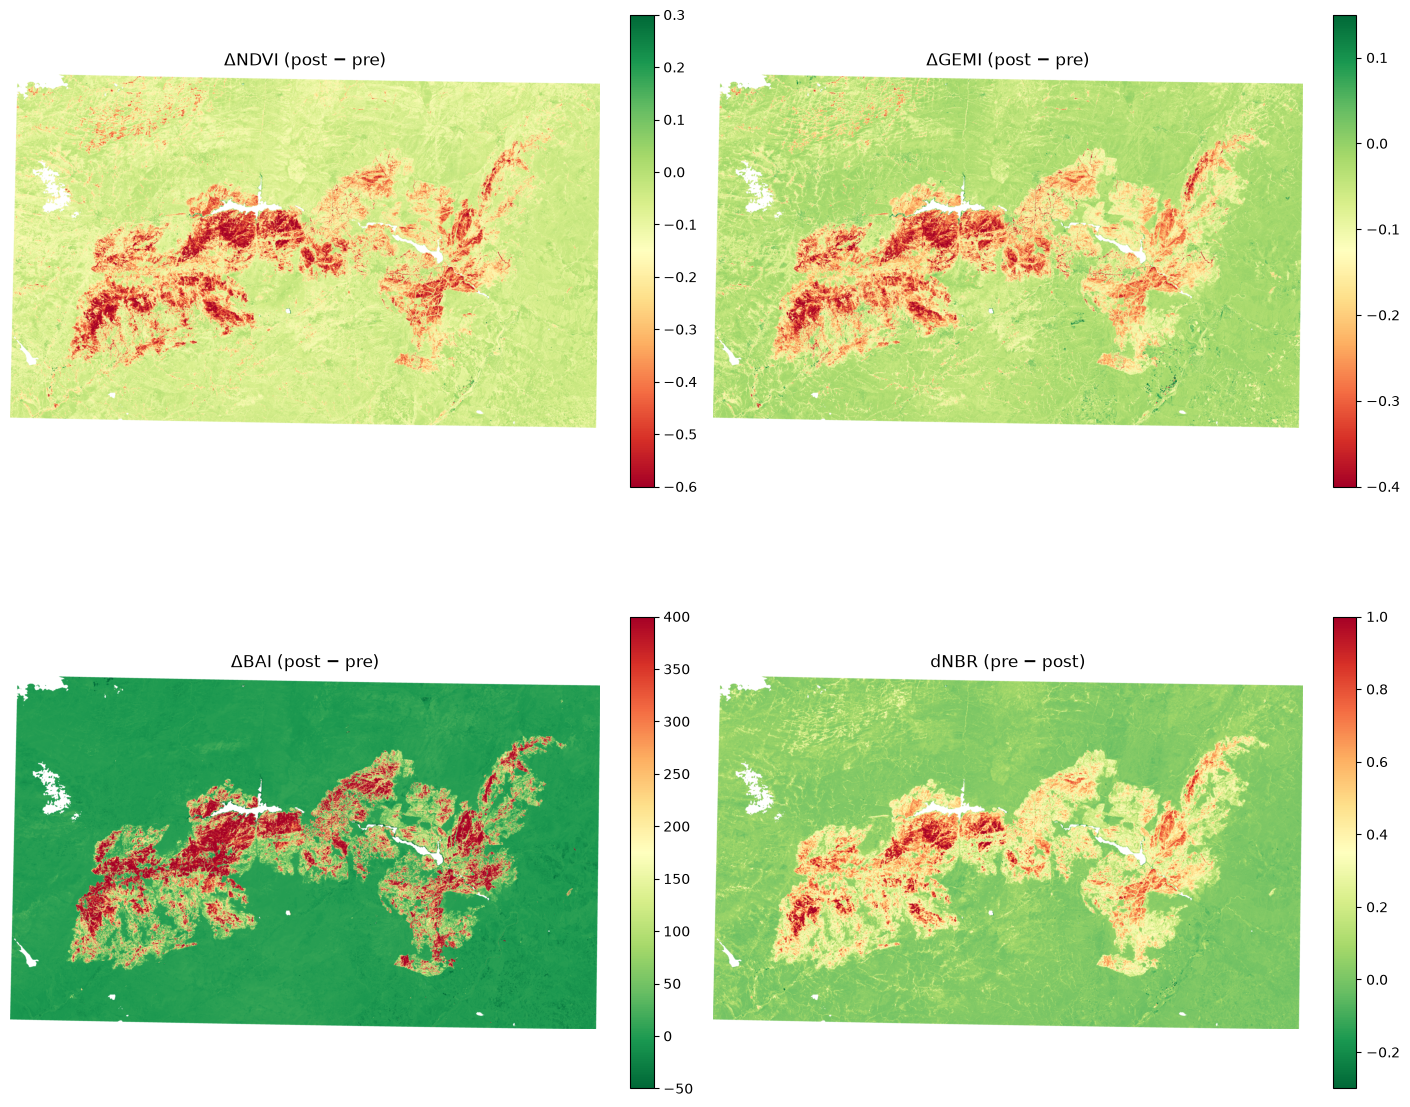

In [6]:
panels = [("dNDVI", "ΔNDVI (post − pre)", "RdYlGn", -0.6, 0.3),
          ("dGEMI", "ΔGEMI (post − pre)", "RdYlGn", -0.4, 0.15),
          ("dBAI", "ΔBAI (post − pre)", "RdYlGn_r", -50, 400),
          ("dNBR", "dNBR (pre − post)", "RdYlGn_r", -0.3, 1.0)]
fig, axs = plt.subplots(2, 2, figsize=(14, 12), constrained_layout=True)
for a, (k, t, cm, vmin, vmax) in zip(axs.ravel(), panels):
    im = a.imshow(idx[k], cmap=cm, vmin=vmin, vmax=vmax)
    fig.colorbar(im, ax=a, shrink=.8)
    a.set_title(t); a.set_axis_off()
fig.savefig(OUT / "step3_indices.png", dpi=120)
plt.show()

## 5. Histogram: the shape that thresholds will use
A histogram counts how many pixels have each value. Most of the area didn't burn, so there is a big peak near **0 change**. The burned pixels form a long "tail" to the right. Notebook 04 decides where to cut that tail.

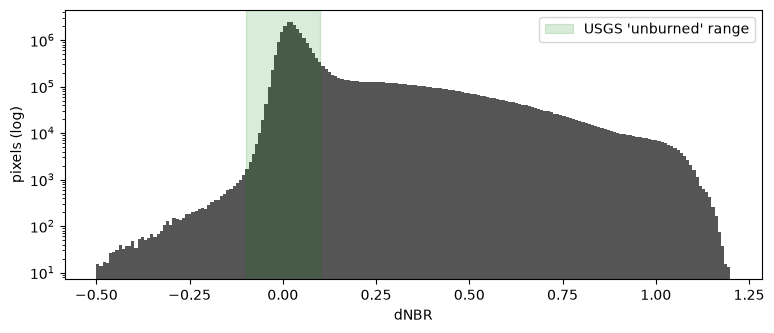

In [7]:
v = idx["dNBR"][np.isfinite(idx["dNBR"])]
plt.figure(figsize=(9, 3.5))
plt.hist(v, bins=200, range=(-0.5, 1.2), color="#555")
plt.axvspan(-0.1, 0.1, color="green", alpha=.15, label="USGS 'unburned' range")
plt.yscale("log"); plt.xlabel("dNBR"); plt.ylabel("pixels (log)"); plt.legend()
plt.show()

## What you learned
- An **index** is a formula combining bands so that one property (greenness, char) stands out.
- **Normalised differences** cancel out overall brightness.
- A **Δ / d** index compares two dates, so only the *change* remains.
- NumPy applies a formula to **every pixel at once**.

**Next:** `04_footprint.ipynb`